# 01. 주간 종목 추천 평가 (2025-2 투자공학, 2026-1 금융공학)

- 매주 과제로 1종목을 추천했다. 평가 규칙: **추천 마감 후 첫 금요일 시가 매수 → 다음 목요일 종가 매도**.
- 추천 종목·주차·마감일은 LearnUs 과제 제출 내역과 제출 파일명에서 옮겨 `configs/picks.csv` 에 적었다.
- 보유 구간이 중간·기말고사 주간과 겹친 주는 실제로 평가하지 않았으므로 제외한다(2026-1 5·11주차).
- 가격: 네이버 금융 일봉(수정주가). 비용: 매수 0.015%, 매도 0.195%(수수료+거래세).
- 방법론 설명과 한계는 `docs/methodology.md` 에 있다.

In [1]:
import sys, yaml
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "Noto Serif CJK JP"]:  # CJK 글꼴은 한글 포함
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
CFG = yaml.safe_load(open(ROOT / "configs/base.yaml"))
RES = ROOT / "results"; (RES / "figures").mkdir(parents=True, exist_ok=True)
from stock_selection.data import load_prices
from stock_selection.backtest import evaluate_picks
from stock_selection import metrics as M
W = CFG["weekly_picks"]
picks = pd.read_csv(ROOT / W["picks_file"], dtype={"ticker": str}, parse_dates=["ref_date"])
picks[["semester", "week", "ref_date", "ticker", "name", "candidate_source", "exam_overlap"]]

,semester,week,ref_date,ticker,name,candidate_source,exam_overlap
0,2025-2,1,2025-09-18,006400,삼성SDI,LLM(Gemini) 시장 분석,False
1,2025-2,2,2025-09-25,009150,삼성전기,ML 샤프지수 + LLM,False
2,2025-2,3,2025-10-10,003670,포스코퓨처엠,LLM(Gemini) 매수의견,False
3,2025-2,4,2025-10-16,002220,한일철강,XGBoost 후보 + LLM,False
4,2025-2,5,2025-10-23,034020,두산에너빌리티,XGBoost 후보 + LLM,False
5,2025-2,6,2025-10-31,086280,현대글로비스,XGBoost 후보 + LLM,False
6,2025-2,7,2025-11-07,316140,우리금융지주,XGBoost 후보 + LLM,False
7,2025-2,8,2025-11-13,005380,현대차,XGBoost 후보 + LLM,False
8,2025-2,9,2025-11-20,068270,셀트리온,XGBoost 후보 + LLM,False
9,2025-2,10,2025-11-27,000020,동화약품,XGBoost 후보 + LLM,False


## 1. 주차별 매매 결과

In [2]:
trades_all = evaluate_picks(picks, load_prices, buy_cost=W["costs"]["buy"], sell_cost=W["costs"]["sell"], benchmark=W["benchmark"])
trades = trades_all[~trades_all["exam_overlap"]].reset_index(drop=True) if W["exclude_exam_weeks"] else trades_all
cols = ["semester", "week", "name", "buy_date", "buy_price", "sell_date", "sell_price", "gross_return", "net_return", "benchmark_return", "exam_overlap"]
trades_all[cols].to_csv(RES / "weekly_trades.csv", index=False)
trades_all[cols].style.format({"buy_price": "{:,.0f}", "sell_price": "{:,.0f}", "gross_return": "{:+.2%}", "net_return": "{:+.2%}", "benchmark_return": "{:+.2%}"})

,semester,week,name,buy_date,buy_price,sell_date,sell_price,gross_return,net_return,benchmark_return,exam_overlap
0,2025-2,1,삼성SDI,2025-09-19,"207,500",2025-09-25,"210,500",+1.45%,+1.23%,+0.29%,False
1,2025-2,2,삼성전기,2025-09-26,"197,700",2025-10-02,"195,800",-0.96%,-1.17%,+3.16%,False
2,2025-2,3,포스코퓨처엠,2025-10-10,"146,400",2025-10-16,"191,500",+30.81%,+30.53%,+4.18%,False
3,2025-2,4,한일철강,2025-10-17,"4,135",2025-10-23,"4,180",+1.09%,+0.88%,+3.02%,False
4,2025-2,5,두산에너빌리티,2025-10-24,"78,300",2025-10-30,"89,700",+14.56%,+14.32%,+4.97%,False
5,2025-2,6,현대글로비스,2025-10-31,"174,400",2025-11-06,"162,400",-6.88%,-7.08%,-1.39%,False
6,2025-2,7,우리금융지주,2025-11-07,"26,900",2025-11-13,"27,000",+0.37%,+0.16%,+5.22%,False
7,2025-2,8,현대차,2025-11-14,"272,500",2025-11-20,"262,000",-3.85%,-4.06%,-1.40%,False
8,2025-2,9,셀트리온,2025-11-21,"174,524",2025-11-27,"176,526",+1.15%,+0.93%,+2.00%,False
9,2025-2,10,동화약품,2025-11-28,"6,200",2025-12-04,"6,220",+0.32%,+0.11%,+0.83%,False


## 2. 학기별 성과표 (시험 주간 제외)

In [3]:
def col(g):
    # 매주 금요일 전량 매수(비중 1) → 목요일 전량 매도(비중 0): 거래 1회당 편도 회전율
    turn = M.turnover(pd.DataFrame(np.tile([[1.0], [0.0]], (len(g), 1)), columns=["pos"]))
    s = M.summary(g["net_return"].reset_index(drop=True), W["periods_per_year"], benchmark=g["benchmark_return"],
                  n_trades=2 * len(g), turnover_per_rebal=turn, rf_annual=W["rf_annual"])
    s["누적수익률(비용 전)"] = M.cumulative_return(g["gross_return"])
    s["아웃샘플 기간"] = f'{g["buy_date"].min()} ~ {g["sell_date"].max()}'
    return s
table = {f"{k} ({len(g)}주)": col(g) for k, g in trades.groupby("semester")}
table[f"전체 ({len(trades)}주)"] = col(trades)
md_table = M.to_markdown(table)
(RES / "weekly_summary.md").write_text(md_table + "\n")
print(md_table)

| 지표 | 2025-2 (10주) | 2026-1 (9주) | 전체 (19주) |
|---|---|---|---|
| 기간 수 | 10 | 9 | 19 |
| 누적수익률 | +35.90% | +72.65% | +134.62% |
| 연환산수익률 | — | — | — |
| 연환산변동성 | 78.98% | 70.71% | 73.95% |
| 샤프 | 2.36 | 4.89 | 3.54 |
| MDD | -10.70% | -4.57% | -10.70% |
| 칼마 | — | — | — |
| 승률 | 70.00% | 55.56% | 63.16% |
| 벤치마크 누적 | +22.63% | +12.60% | +38.09% |
| 벤치마크 초과 기간 | 3 | 6 | 9 |
| 거래 횟수 | 20 | 18 | 38 |
| 회전율(회당) | 100.00% | 100.00% | 100.00% |
| 누적수익률(비용 전) | +38.78% | +75.94% | +144.18% |
| 아웃샘플 기간 | 2025-09-19 ~ 2025-12-04 | 2026-03-20 ~ 2026-06-11 | 2025-09-19 ~ 2026-06-11 |


## 3. 민감도: 시험 주간 포함 / 단순 합산

In [4]:
rows = {}
for k, g in trades_all.groupby("semester"):
    ex = g[~g["exam_overlap"]]
    rows[k] = {"시험 주간 제외(본 결과)": M.cumulative_return(ex["net_return"]),
               "시험 주간 포함": M.cumulative_return(g["net_return"]),
               "단순 합산(제외 기준)": ex["net_return"].sum()}
sens = pd.DataFrame(rows)
sens.to_csv(RES / "weekly_sensitivity.csv")
sens.style.format("{:+.2%}")

,2025-2,2026-1
시험 주간 제외(본 결과),+35.90%,+72.65%
시험 주간 포함,+35.90%,+115.76%
단순 합산(제외 기준),+35.87%,+59.79%


## 4. 결과가 무엇에 기대고 있는가

- 2026-1은 9주 중 5주가 SK하이닉스다. 같은 기간 SK하이닉스 단순 보유, KOSPI 보유와 비교한다.
- 상위 몇 주를 빼면 결과가 얼마나 남는지(집중도)를 본다.

In [5]:
def contrib(g, top=3):
    r = g.sort_values("net_return", ascending=False)["net_return"]
    return {"전체 누적": M.cumulative_return(g["net_return"]),
            f"상위 {top}주 제외 누적": M.cumulative_return(r.iloc[top:]),
            "상위 1주 제외 누적": M.cumulative_return(r.iloc[1:])}
conc = pd.DataFrame({k: contrib(g) for k, g in trades.groupby("semester")})

g26 = trades[trades["semester"] == "2026-1"]
hx = g26[g26["ticker"] == "000660"]
px = load_prices("000660"); kospi = load_prices("KOSPI")
d0, d1 = pd.Timestamp(hx["buy_date"].min()), pd.Timestamp(hx["sell_date"].max())
bh = {"SK하이닉스 주간 매매(본 전략, 비용 후)": M.cumulative_return(hx["net_return"]),
      "SK하이닉스 단순 보유(같은 구간)": px.at[d1, "close"] / px.at[d0, "open"] - 1,
      "KOSPI 단순 보유(같은 구간)": kospi.at[d1, "close"] / kospi.at[d0, "open"] - 1}
s0, s1 = pd.Timestamp(g26["buy_date"].min()), pd.Timestamp(g26["sell_date"].max())
bh["KOSPI 단순 보유(2026-1 전체 평가 구간)"] = kospi.at[s1, "close"] / kospi.at[s0, "open"] - 1
print(f"SK하이닉스 구간: {d0.date()} ~ {d1.date()}")
display(conc.style.format("{:+.2%}"), pd.Series(bh).to_frame("누적").style.format("{:+.2%}"))
conc.to_csv(RES / "weekly_concentration.csv"); pd.Series(bh).to_csv(RES / "weekly_vs_buyhold.csv")

SK하이닉스 구간: 2026-05-08 ~ 2026-06-11


,2025-2,2026-1
전체 누적,+35.90%,+72.65%
상위 3주 제외 누적,-10.04%,+2.79%
상위 1주 제외 누적,+4.11%,+39.72%


,누적
"SK하이닉스 주간 매매(본 전략, 비용 후)",+37.69%
SK하이닉스 단순 보유(같은 구간),+32.06%
KOSPI 단순 보유(같은 구간),+5.58%
KOSPI 단순 보유(2026-1 전체 평가 구간),+33.55%


## 5. 누적 곡선

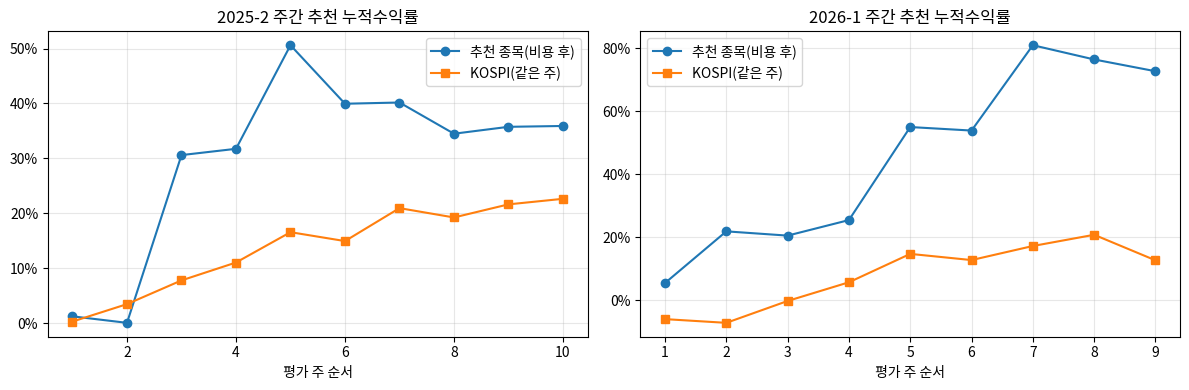

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (k, g) in zip(axes, trades.groupby("semester")):
    x = range(1, len(g) + 1)
    ax.plot(x, (1 + g["net_return"]).cumprod().values - 1, marker="o", label="추천 종목(비용 후)")
    ax.plot(x, (1 + g["benchmark_return"]).cumprod().values - 1, marker="s", label="KOSPI(같은 주)")
    ax.set_title(f"{k} 주간 추천 누적수익률"); ax.set_xlabel("평가 주 순서"); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(RES / "figures/weekly_cumulative.png", dpi=150); plt.show()